In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# ============================================================
# 1. DATASET DISCOVERY
# ============================================================
# Purpose:
# Identify all MATLAB (.mat) files belonging to the Figshare
# brain tumor dataset.
#
# The dataset is distributed across four folders. Instead of
# manually specifying each folder, we recursively search the
# entire data directory.
#
# cvind.mat is excluded because it contains cross-validation
# indices rather than an individual MRI sample.
# ============================================================
data_root = Path("../data/raw")

mat_files = sorted(
    p for p in data_root.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"Total .mat files found: {len(mat_files)}")
print("\nFirst 5 files:")

for f in mat_files[:5]:
    print(f)

Total .mat files found: 3064

First 5 files:
..\data\raw\brainTumorDataPublic_15332298\1533.mat
..\data\raw\brainTumorDataPublic_15332298\1534.mat
..\data\raw\brainTumorDataPublic_15332298\1535.mat
..\data\raw\brainTumorDataPublic_15332298\1536.mat
..\data\raw\brainTumorDataPublic_15332298\1537.mat


In [ ]:
# ============================================================
# 2. MATLAB FILE STRUCTURE INSPECTION
# ============================================================
# Purpose:
# Inspect the internal structure of one MRI sample before
# processing the complete dataset.
#
# The Figshare dataset uses MATLAB v7.3 format, which is based
# on HDF5. Therefore, h5py is used instead of scipy.loadmat().
# ============================================================
import h5py
# Select the first MRI file as a representative sample
sample_file = mat_files[0]

print("Loading:", sample_file)

# Open the MATLAB v7.3 file using h5py
with h5py.File(sample_file, "r") as f:
    print("Keys:", list(f.keys()))

Loading: ..\data\raw\brainTumorDataPublic_15332298\1533.mat
Keys: ['cjdata']


In [5]:
# on 1 mri image
with h5py.File(sample_file, "r") as f:
    cjdata = f["cjdata"]
    
    print("Fields inside cjdata:")
    print(list(cjdata.keys()))

Fields inside cjdata:
['PID', 'image', 'label', 'tumorBorder', 'tumorMask']


In [ ]:
# ============================================================
# 3. INSPECT CJDATA STRUCTURE
# ============================================================
# Purpose:
# Identify the fields available for each MRI sample.
#
# According to the dataset documentation, cjdata contains:
# - PID          : Patient identifier
# - image        : MRI image
# - label        : Tumor class
# - tumorBorder  : Tumor boundary coordinates
# - tumorMask    : Ground-truth tumor segmentation mask
# ============================================================
with h5py.File(sample_file, "r") as f:
    cjdata = f["cjdata"]

    print("Fields:")
    for field in cjdata.keys():
        print(field)

Fields:
PID
image
label
tumorBorder
tumorMask


In [ ]:
# ============================================================
# 4. FIELD DIMENSIONS AND DATA TYPES
# ============================================================
# Purpose:
# Examine the shape and data type of each field before
# extracting the dataset metadata.
#
# This helps us understand how MATLAB stored each variable
# and prevents incorrect interpretation of the data.
# ============================================================


with h5py.File(sample_file, "r") as f:
    cjdata = f["cjdata"]

    for field in cjdata.keys():
        item = cjdata[field]
        print(f"{field}: shape={item.shape}, dtype={item.dtype}")

PID: shape=(6, 1), dtype=uint16
image: shape=(512, 512), dtype=int16
label: shape=(1, 1), dtype=float64
tumorBorder: shape=(1, 34), dtype=float64
tumorMask: shape=(512, 512), dtype=uint8


In [ ]:
# ============================================================
# 5. SINGLE-SAMPLE EXTRACTION
# ============================================================
# Purpose:
# Extract the MRI image, tumor label, patient ID, and tumor
# mask from one sample.
#
# This step verifies that the important information can be
# correctly accessed before processing all 3,064 images.
# ============================================================
with h5py.File(sample_file, "r") as f:
    cjdata = f["cjdata"]

    image = np.array(cjdata["image"])
    label = np.array(cjdata["label"]).squeeze()
    pid = np.array(cjdata["PID"]).squeeze()
    tumor_mask = np.array(cjdata["tumorMask"])

print("Image shape:", image.shape)
print("Label:", label)
print("PID:", pid)
print("Tumor mask shape:", tumor_mask.shape)
print("Tumor pixels:", np.sum(tumor_mask > 0))

Image shape: (512, 512)
Label: 3.0
PID: [49 48 52 48 49 57]
Tumor mask shape: (512, 512)
Tumor pixels: 1123


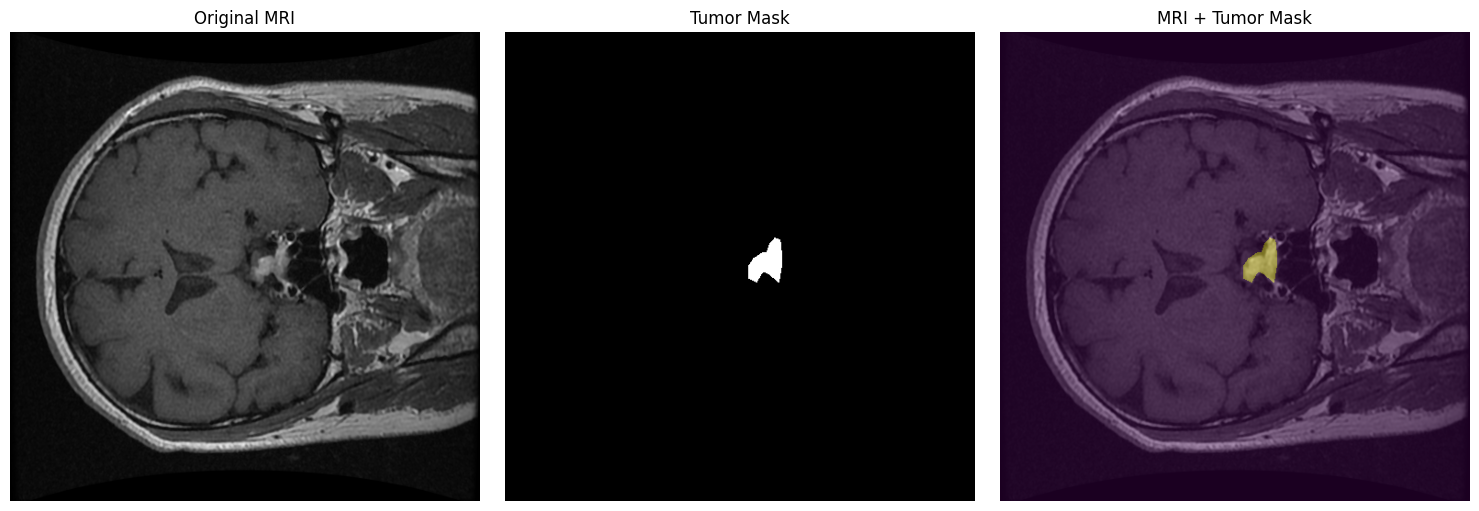

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original MRI")
axes[0].axis("off")

axes[1].imshow(tumor_mask, cmap="gray")
axes[1].set_title("Tumor Mask")
axes[1].axis("off")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(tumor_mask, alpha=0.4)
axes[2].set_title("MRI + Tumor Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 6. DATASET METADATA EXTRACTION
# ============================================================
# Purpose:
# Process all 3,064 MRI files and create a structured metadata
# table.
#
# We do NOT store all MRI images in the dataframe because this
# would unnecessarily consume memory.
#
# Instead, we store:
# - File information
# - Patient ID
# - Tumor label/class
# - Image dimensions
# - Tumor pixel count
# - Tumor area percentage
#
# This metadata table will be used for the majority of our EDA.
# ============================================================

import pandas as pd
from tqdm.auto import tqdm

CLASS_NAMES = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary"
}

records = []

for file_path in tqdm(mat_files, desc="Processing Figshare files"):
    try:
        with h5py.File(file_path, "r") as f:
            cjdata = f["cjdata"]

            # Basic information
            image_shape = tuple(cjdata["image"].shape)

            label = int(np.array(cjdata["label"]).squeeze())

            pid_raw = np.array(cjdata["PID"]).squeeze()

            # Convert PID to a readable value
            if pid_raw.size > 1:
                pid = "".join(chr(int(x)) for x in pid_raw.flatten())
            else:
                pid = str(int(pid_raw))

            # Tumor mask statistics
            tumor_mask = np.array(cjdata["tumorMask"])
            tumor_pixels = int(np.sum(tumor_mask > 0))
            total_pixels = tumor_mask.size
            tumor_area_percentage = (tumor_pixels / total_pixels) * 100

            records.append({
                "file": str(file_path),
                "filename": file_path.name,
                "pid": pid,
                "label": label,
                "class": CLASS_NAMES.get(label, "Unknown"),
                "height": image_shape[0],
                "width": image_shape[1],
                "tumor_pixels": tumor_pixels,
                "tumor_area_percentage": tumor_area_percentage
            })

    except Exception as e:
        print(f"Error processing {file_path}: {e}")

figshare_df = pd.DataFrame(records)

print("Number of records:", len(figshare_df))
figshare_df.head()

Processing Figshare files:   0%|          | 0/3064 [00:00<?, ?it/s]

Number of records: 3064


,file,filename,pid,label,class,height,width,tumor_pixels,tumor_area_percentage
0,..\data\raw\brainTumorDataPublic_15332298\1533...,1533.mat,104019,3,Pituitary,512,512,1123,0.428391
1,..\data\raw\brainTumorDataPublic_15332298\1534...,1534.mat,104019,3,Pituitary,512,512,1262,0.481415
2,..\data\raw\brainTumorDataPublic_15332298\1535...,1535.mat,104019,3,Pituitary,512,512,1604,0.611877
3,..\data\raw\brainTumorDataPublic_15332298\1536...,1536.mat,104019,3,Pituitary,512,512,1307,0.498581
4,..\data\raw\brainTumorDataPublic_15332298\1537...,1537.mat,104019,3,Pituitary,512,512,1205,0.459671


In [ ]:
# ============================================================
# 7. DATASET INTEGRITY VALIDATION
# ============================================================
# Purpose:
# Verify that the extracted dataset matches the official
# dataset description.
#
# We check:
# - Total number of images
# - Number of unique patients
# - Class distribution
# - Image dimensions
# - Missing metadata
# ============================================================
print("Total images:", len(figshare_df))
print("Unique patients:", figshare_df["pid"].nunique())

print("\nClass distribution:")
print(figshare_df["class"].value_counts())

print("\nImage dimensions:")
print(figshare_df[["height", "width"]].value_counts())

print("\nMissing values:")
print(figshare_df.isnull().sum())

Total images: 3064
Unique patients: 233

Class distribution:
class
Glioma        1426
Pituitary      930
Meningioma     708
Name: count, dtype: int64

Image dimensions:
height  width
512     512      3049
256     256        15
Name: count, dtype: int64

Missing values:
file                     0
filename                 0
pid                      0
label                    0
class                    0
height                   0
width                    0
tumor_pixels             0
tumor_area_percentage    0
dtype: int64


In [ ]:
# ============================================================
# 8. PATIENT-LEVEL ANALYSIS
# ============================================================
# Purpose:
# Determine how many MRI images are associated with each
# patient.
#
# This is critical because the dataset contains 3,064 images
# but only 233 patients. Multiple images from the same patient
# are therefore not statistically independent.
#
# This analysis will also guide our future train/validation/test
# splitting strategy and help prevent patient-level data leakage.
# ============================================================

# Count the number of MRI images belonging to each patient
patient_counts = figshare_df["pid"].value_counts()

print("Number of patients:", len(patient_counts))
print("\nImages per patient:")
print(patient_counts.describe())

print("\nMinimum images per patient:", patient_counts.min())
print("Maximum images per patient:", patient_counts.max())
print("Mean images per patient:", patient_counts.mean())
print("Median images per patient:", patient_counts.median())

Number of patients: 233

Images per patient:
count    233.000000
mean      13.150215
std        7.655779
min        1.000000
25%        7.000000
50%       13.000000
75%       18.000000
max       38.000000
Name: count, dtype: float64

Minimum images per patient: 1
Maximum images per patient: 38
Mean images per patient: 13.150214592274677
Median images per patient: 13.0


In [ ]:
# ============================================================
# 9. RESULTS DIRECTORY
# ============================================================
# Purpose:
# Create a dedicated directory for saving EDA figures and
# derived metadata.
#
# This keeps the repository organized and makes our results
# reproducible.
# ============================================================
from pathlib import Path

results_dir = Path("../results/eda")
results_dir.mkdir(parents=True, exist_ok=True)

print("EDA results folder ready:", results_dir)

EDA results folder ready: ..\results\eda


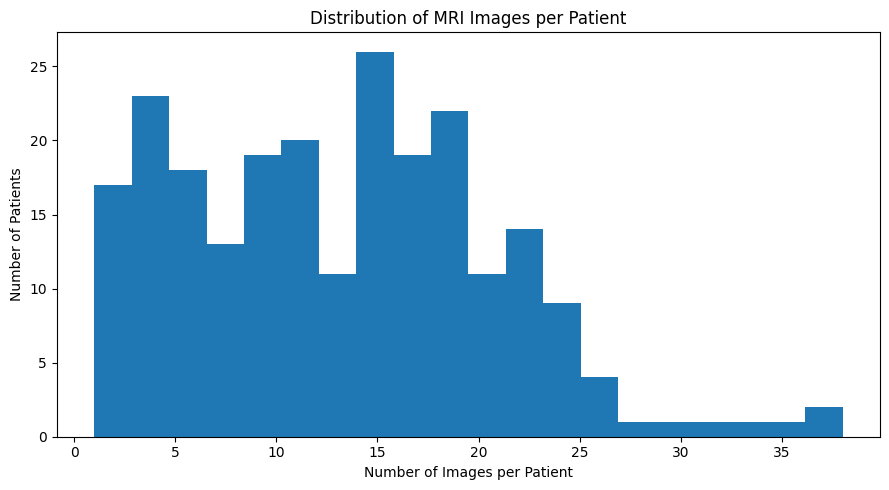

In [ ]:
# ============================================================
# 10. DISTRIBUTION OF IMAGES PER PATIENT
# ============================================================
# Purpose:
# Visualize how MRI images are distributed across patients.
#
# This helps us identify whether some patients contribute
# substantially more images than others.
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(patient_counts, bins=20)

plt.title("Distribution of MRI Images per Patient")
plt.xlabel("Number of Images per Patient")
plt.ylabel("Number of Patients")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_images_per_patient.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# ============================================================
# 11. IMAGE DIMENSION QUALITY CHECK
# ============================================================
# Purpose:
# Identify images whose dimensions differ from the dominant
# 512 × 512 resolution.
#
# We found that 3,049 images are 512 × 512 while 15 images
# are 256 × 256. These images must be investigated before
# deciding on preprocessing.
#
# We do NOT remove or resize them at this stage.
# ============================================================

unusual_dims = figshare_df[
    (figshare_df["height"] != 512) |
    (figshare_df["width"] != 512)
]

print(
    "Number of non-512×512 images:",
    len(unusual_dims)
)

print(
    unusual_dims[
        [
            "filename",
            "pid",
            "class",
            "height",
            "width"
        ]
    ].to_string(index=False)
)

Number of non-512×512 images: 15
filename    pid     class  height  width
1070.mat 108931 Pituitary     256    256
1071.mat 108931 Pituitary     256    256
1072.mat 108931 Pituitary     256    256
1073.mat 108931 Pituitary     256    256
1074.mat 108931 Pituitary     256    256
1075.mat 108931 Pituitary     256    256
1076.mat 108931 Pituitary     256    256
1203.mat 108931 Pituitary     256    256
1204.mat 108931 Pituitary     256    256
1205.mat 108931 Pituitary     256    256
1206.mat 108931 Pituitary     256    256
1207.mat 108931 Pituitary     256    256
 955.mat 108931 Pituitary     256    256
 956.mat 108931 Pituitary     256    256
 957.mat 108931 Pituitary     256    256


In [19]:
# ============================================================
# 12. SAVE DERIVED METADATA
# ============================================================
# Purpose:
# Save the metadata generated during EDA so that the analysis
# can be reproduced without repeatedly scanning all 3,064
# MATLAB files.
#
# This CSV contains metadata/statistics, NOT the MRI images.
# ============================================================

metadata_path = results_dir / "figshare_metadata.csv"

figshare_df.to_csv(
    metadata_path,
    index=False
)

print("Metadata saved to:", metadata_path)

Metadata saved to: ..\results\eda\figshare_metadata.csv


In [20]:
# ============================================================
# 13. CLASS DISTRIBUTION ANALYSIS
# ============================================================
# Purpose:
# Calculate the number and percentage of images belonging to
# each tumor class.
# ============================================================

# Define the desired class order for consistent reporting
class_order = ["Meningioma", "Glioma", "Pituitary"]

# Calculate class counts
class_counts = (
    figshare_df["class"]
    .value_counts()
    .reindex(class_order)
)

# Calculate class percentages
class_percentages = (
    class_counts / len(figshare_df) * 100
)

# Create a summary table
class_summary = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage": class_percentages.round(2)
})

print(class_summary)

            Image Count  Percentage
class                              
Meningioma          708       23.11
Glioma             1426       46.54
Pituitary           930       30.35


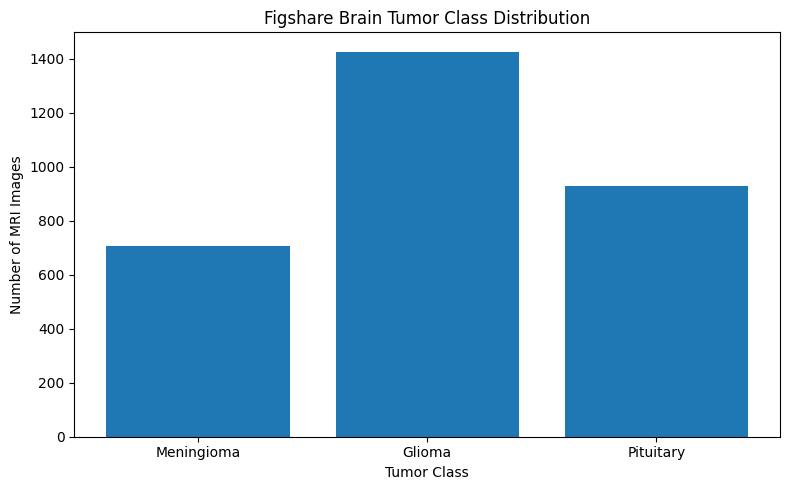

In [ ]:
# ============================================================
# 14. CLASS DISTRIBUTION VISUALIZATION
# ============================================================
# Purpose:
# Visualize the number of MRI images in each tumor category.
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    class_summary.index,
    class_summary["Image Count"]
)

plt.title("Figshare Brain Tumor Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of MRI Images")

plt.tight_layout()

# Save the figure for the EDA report
plt.savefig(
    results_dir / "figshare_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# ============================================================
# 15. PATIENT-LEVEL CLASS DISTRIBUTION
# ============================================================
# Purpose:
# Determine the number of unique patients associated with each
# tumor class.
# ============================================================

# Keep one tumor class per patient
patient_class_df = (
    figshare_df[
        ["pid", "class"]
    ]
    .drop_duplicates()
)

# Count unique patients in each class
patient_class_counts = (
    patient_class_df["class"]
    .value_counts()
    .reindex(class_order)
)

print("Patients per tumor class:")
print(patient_class_counts)

Patients per tumor class:
class
Meningioma    82
Glioma        89
Pituitary     62
Name: count, dtype: int64


In [23]:
# ============================================================
# 16. PATIENT-CLASS CONSISTENCY CHECK
# ============================================================
# Purpose:
# Determine whether any patient has MRI images associated with
# more than one tumor class.
#
# A patient appearing in multiple classes would be important
# to understand before creating patient-level train/test splits.
# ============================================================

classes_per_patient = (
    figshare_df
    .groupby("pid")["class"]
    .nunique()
)

multi_class_patients = classes_per_patient[
    classes_per_patient > 1
]

print(
    "Patients with more than one tumor class:",
    len(multi_class_patients)
)

if len(multi_class_patients) > 0:
    print("\nPatients with multiple classes:")
    print(multi_class_patients)
else:
    print("\nEvery patient is associated with a single tumor class.")

Patients with more than one tumor class: 0

Every patient is associated with a single tumor class.


## 17. Image Resolution Analysis

Most MRI images in the dataset have a resolution of 512×512 pixels.
However, a small number of images have a resolution of 256×256.

These images are investigated separately to determine whether the
resolution difference represents legitimate variation or a data
quality problem.

The images will not be removed solely because their dimensions
differ.

In [25]:
# ============================================================
# 17. IDENTIFY NON-STANDARD IMAGE DIMENSIONS
# ============================================================

# Identify images whose dimensions differ from the dominant
# 512 × 512 resolution.
unusual_dims = figshare_df[
    (figshare_df["height"] != 512) |
    (figshare_df["width"] != 512)
].copy()

print(
    "Number of non-512×512 images:",
    len(unusual_dims)
)

print(
    unusual_dims[
        [
            "filename",
            "pid",
            "class",
            "height",
            "width"
        ]
    ].to_string(index=False)
)

Number of non-512×512 images: 15
filename    pid     class  height  width
1070.mat 108931 Pituitary     256    256
1071.mat 108931 Pituitary     256    256
1072.mat 108931 Pituitary     256    256
1073.mat 108931 Pituitary     256    256
1074.mat 108931 Pituitary     256    256
1075.mat 108931 Pituitary     256    256
1076.mat 108931 Pituitary     256    256
1203.mat 108931 Pituitary     256    256
1204.mat 108931 Pituitary     256    256
1205.mat 108931 Pituitary     256    256
1206.mat 108931 Pituitary     256    256
1207.mat 108931 Pituitary     256    256
 955.mat 108931 Pituitary     256    256
 956.mat 108931 Pituitary     256    256
 957.mat 108931 Pituitary     256    256


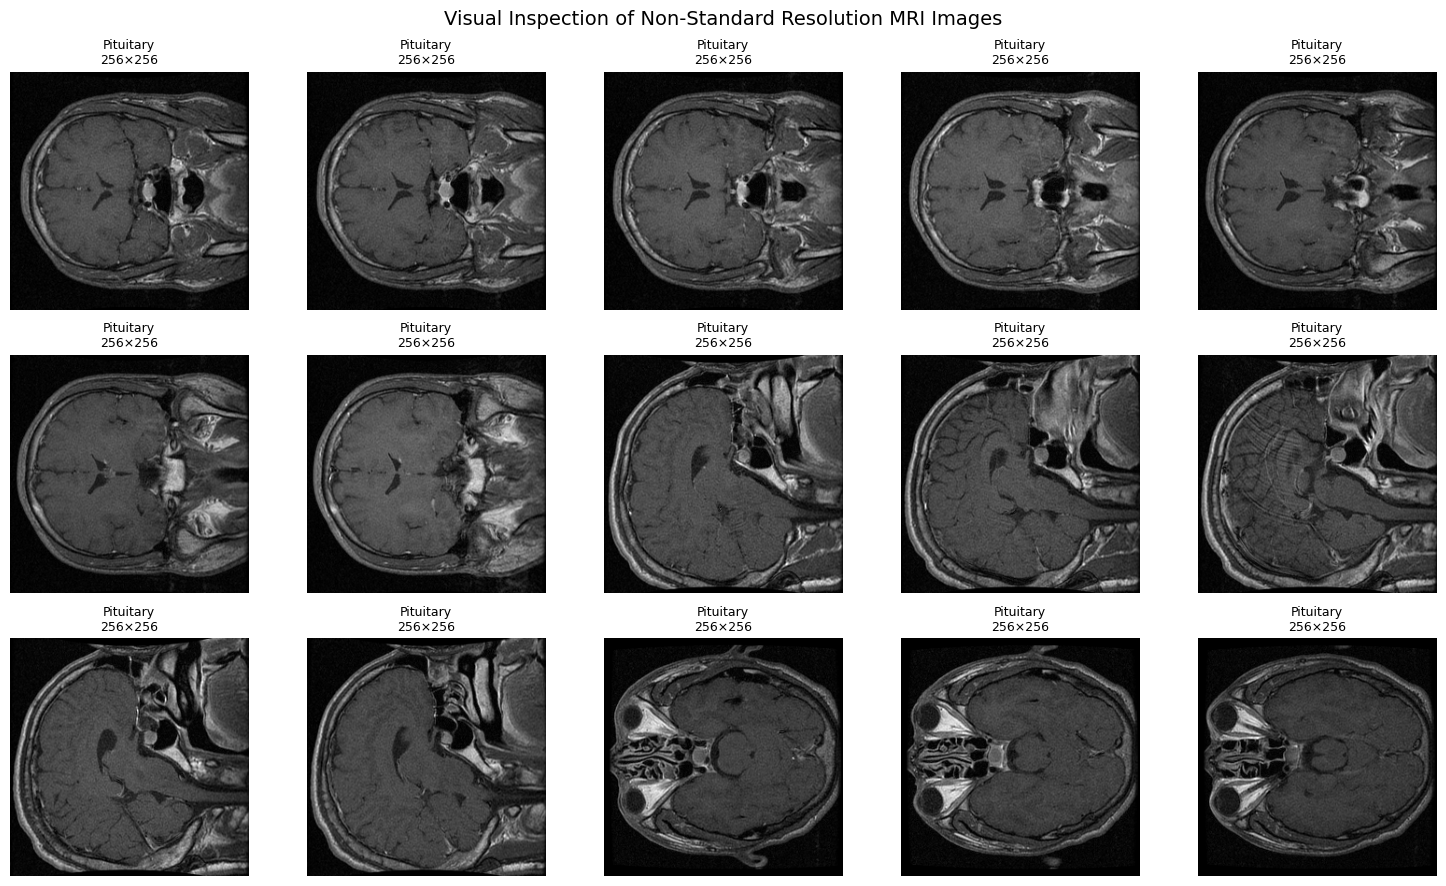

In [26]:
# ============================================================
# 18. VISUAL INSPECTION OF NON-STANDARD RESOLUTION IMAGES
# ============================================================
# Purpose:
# Visually inspect the 15 images stored at 256×256 resolution.
#
# We want to determine whether they are valid MRI scans or
# potential data-quality problems.
# ============================================================

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9)
)

for ax, (_, row) in zip(
    axes.flat,
    unusual_dims.iterrows()
):

    # Open the corresponding MATLAB file
    with h5py.File(row["file"], "r") as f:

        # Extract the MRI image
        image = np.array(
            f["cjdata"]["image"]
        )

    # Display the image
    ax.imshow(
        image,
        cmap="gray"
    )

    # Add class and resolution information
    ax.set_title(
        f"{row['class']}\n"
        f"{row['height']}×{row['width']}",
        fontsize=9
    )

    ax.axis("off")

plt.suptitle(
    "Visual Inspection of Non-Standard Resolution MRI Images",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_nonstandard_resolution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The dataset contains 15 images with 256×256 resolution compared with the dominant 512×512 resolution. Visual inspection confirms that these images are valid MRI samples. Resolution standardization will therefore be handled during preprocessing rather than removing these samples

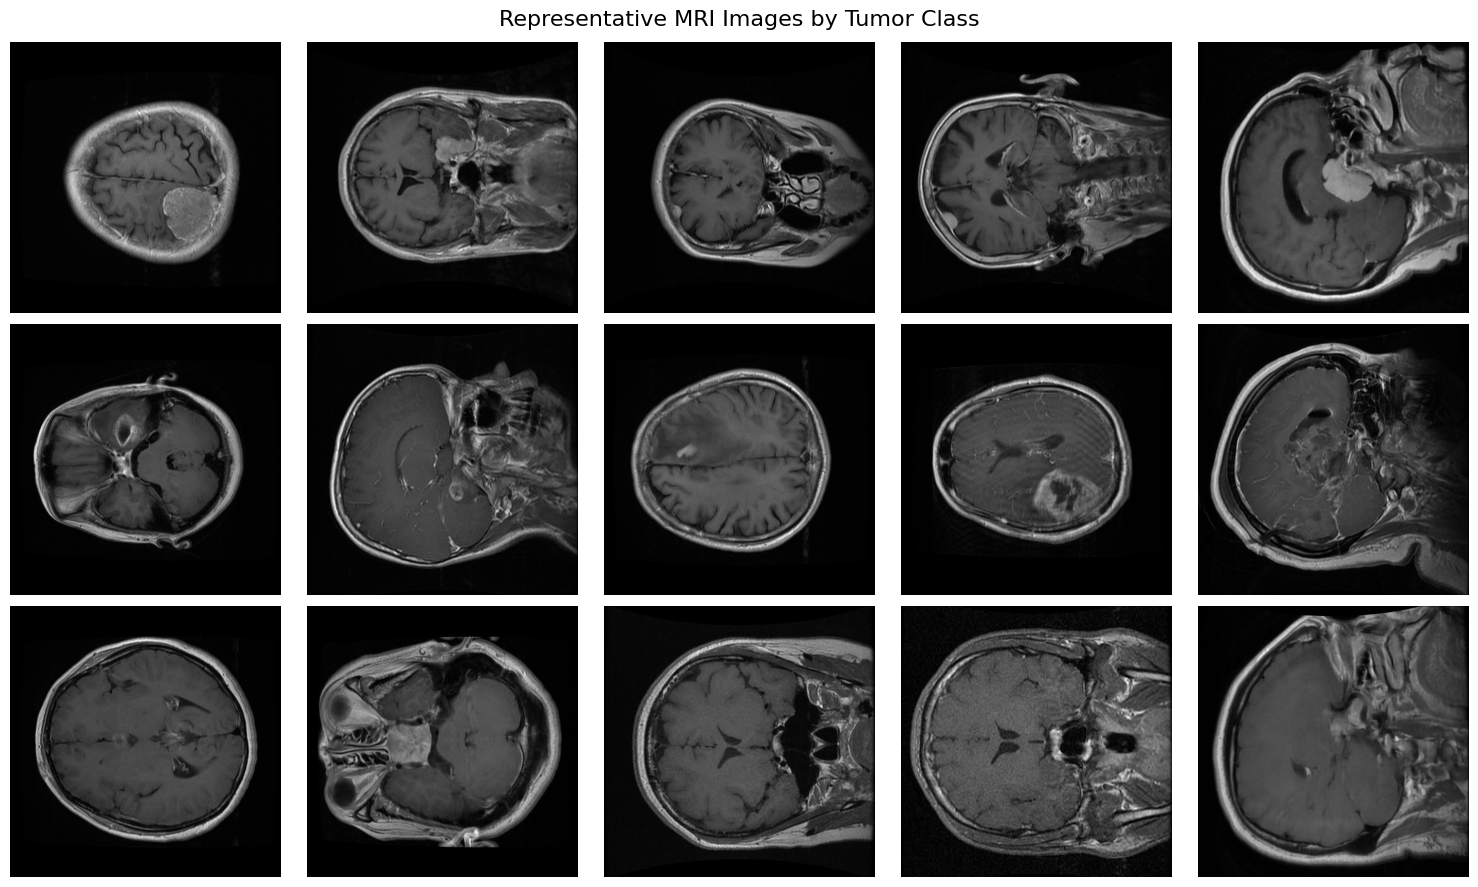

In [27]:
# ============================================================
# 19. REPRESENTATIVE MRI VISUALIZATION
# ============================================================
# Purpose:
# Display representative MRI images from each tumor class.
#
# A fixed random seed is used so that the same images are selected
# whenever the notebook is executed again.
# ============================================================

# Number of representative images per class
n_samples = 5

# Fixed random seed for reproducibility
random_seed = 42

# Create a figure with one row per tumor class
fig, axes = plt.subplots(
    len(class_order),
    n_samples,
    figsize=(15, 9)
)

# Loop through each tumor class
for row_idx, tumor_class in enumerate(class_order):

    # Select all images belonging to the current class
    class_data = figshare_df[
        figshare_df["class"] == tumor_class
    ]

    # Randomly select representative images
    sampled_data = class_data.sample(
        n=n_samples,
        random_state=random_seed
    )

    # Display each selected MRI
    for col_idx, (_, row) in enumerate(
        sampled_data.iterrows()
    ):

        # Open the MATLAB file
        with h5py.File(row["file"], "r") as f:

            # Extract the MRI image
            image = np.array(
                f["cjdata"]["image"]
            )

        # Display MRI
        axes[row_idx, col_idx].imshow(
            image,
            cmap="gray"
        )

        # Add class label to the first image in each row
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(
                tumor_class,
                fontsize=12
            )

        axes[row_idx, col_idx].axis("off")

# Add overall figure title
plt.suptitle(
    "Representative MRI Images by Tumor Class",
    fontsize=16
)

plt.tight_layout()

# Save the figure for the EDA report
plt.savefig(
    results_dir / "figshare_representative_mri.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 20. Tumor Mask Visualization

The Figshare dataset provides a manually delineated tumor mask
for each MRI image.

The tumor mask identifies the pixels belonging to the tumor
region and provides ground-truth spatial information.

This annotation is particularly valuable for our project because
it can later be used to evaluate whether Vision Transformer
attention and explainability maps focus on clinically relevant
tumor regions.

C:\Users\Vishal\AppData\Local\Temp\ipykernel_26216\1926939620.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


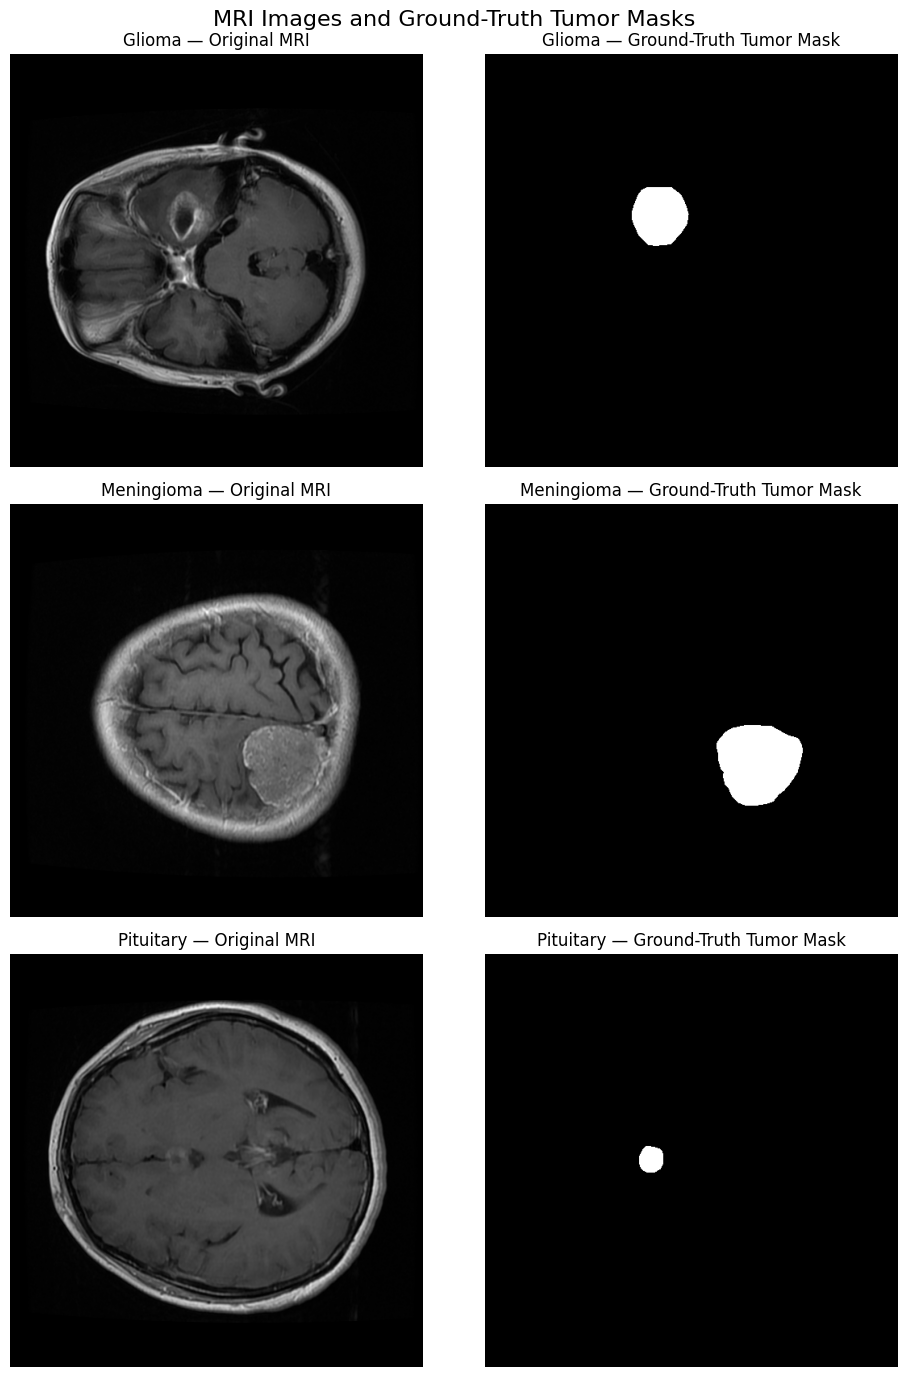

In [28]:
# ============================================================
# 20. TUMOR MASK VISUALIZATION
# ============================================================
# Purpose:
# Display representative MRI images alongside their
# corresponding ground-truth tumor masks.
# ============================================================

# Select one representative image from each class
mask_samples = (
    figshare_df
    .groupby("class", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=1,
            random_state=42
        )
    )
)

# Create a figure with three rows and two columns
fig, axes = plt.subplots(
    3,
    2,
    figsize=(10, 14)
)

for row_idx, (_, row) in enumerate(
    mask_samples.iterrows()
):

    # Open the corresponding MATLAB file
    with h5py.File(row["file"], "r") as f:

        # Extract MRI and tumor mask
        image = np.array(
            f["cjdata"]["image"]
        )

        tumor_mask = np.array(
            f["cjdata"]["tumorMask"]
        )

    # Display original MRI
    axes[row_idx, 0].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 0].set_title(
        f"{row['class']} — Original MRI"
    )

    axes[row_idx, 0].axis("off")

    # Display ground-truth tumor mask
    axes[row_idx, 1].imshow(
        tumor_mask,
        cmap="gray"
    )

    axes[row_idx, 1].set_title(
        f"{row['class']} — Ground-Truth Tumor Mask"
    )

    axes[row_idx, 1].axis("off")

plt.suptitle(
    "MRI Images and Ground-Truth Tumor Masks",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_tumor_masks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. MRI and Tumor Mask Overlay

The ground-truth tumor mask is overlaid on the original MRI to
visualize the spatial location and extent of the tumor.

This provides an intuitive representation of the regions that
contain tumor tissue.

The resulting visualization also establishes a foundation for
future comparison between ground-truth tumor regions and
Vision Transformer attention/explainability maps.

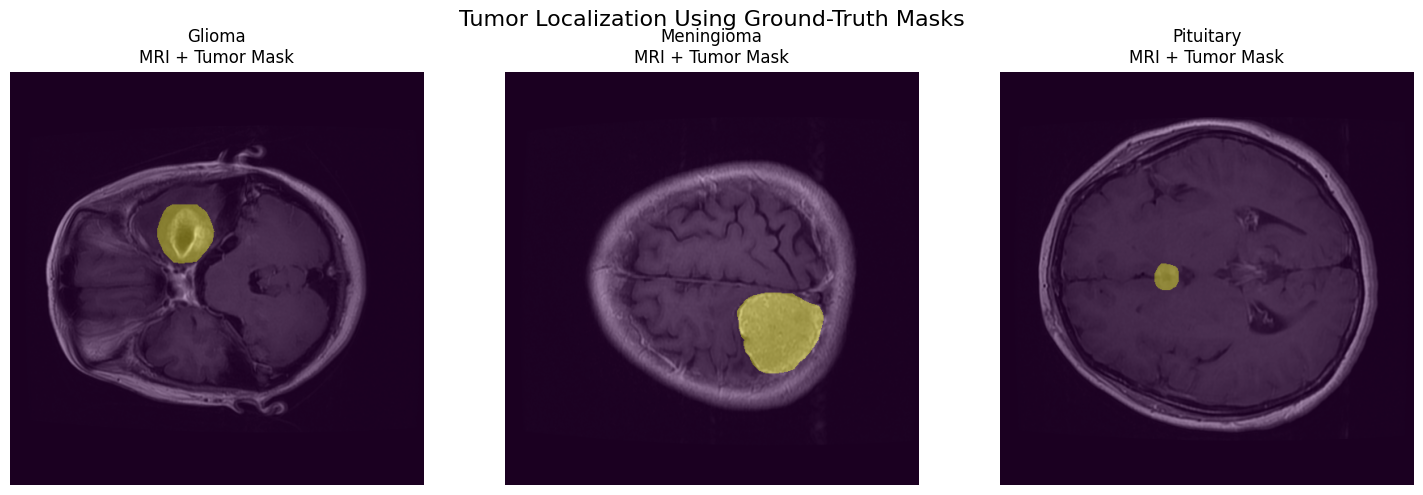

In [29]:
# ============================================================
# 21. MRI + TUMOR MASK OVERLAY
# ============================================================
# Purpose:
# Visualize the tumor location directly on the original MRI.
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

for ax, (_, row) in zip(
    axes,
    mask_samples.iterrows()
):

    # Open MATLAB file
    with h5py.File(row["file"], "r") as f:

        # Extract MRI image
        image = np.array(
            f["cjdata"]["image"]
        )

        # Extract ground-truth tumor mask
        tumor_mask = np.array(
            f["cjdata"]["tumorMask"]
        )

    # Display original MRI
    ax.imshow(
        image,
        cmap="gray"
    )

    # Overlay tumor mask
    ax.imshow(
        tumor_mask,
        alpha=0.4
    )

    ax.set_title(
        f"{row['class']}\nMRI + Tumor Mask"
    )

    ax.axis("off")

plt.suptitle(
    "Tumor Localization Using Ground-Truth Masks",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_tumor_mask_overlays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# ============================================================
# 22.1 OVERALL TUMOR AREA STATISTICS
# ============================================================
# Purpose:
# Summarize the distribution of tumor area percentages across
# all 3,064 MRI images.
# ============================================================

tumor_area_stats = figshare_df[
    "tumor_area_percentage"
].describe()

print("Tumor Area Percentage Statistics:")
print(tumor_area_stats)

Tumor Area Percentage Statistics:
count    3064.000000
mean        1.690056
std         1.378971
min         0.097275
25%         0.653744
50%         1.285553
75%         2.320480
max         9.712601
Name: tumor_area_percentage, dtype: float64


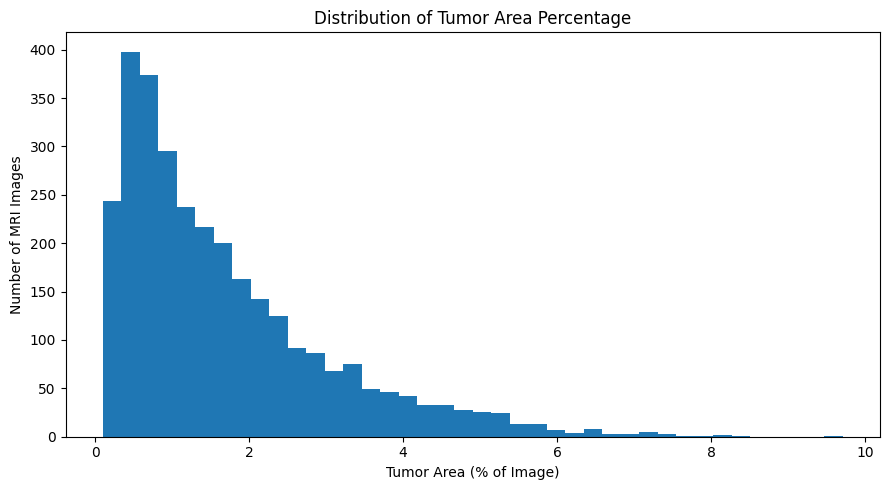

In [31]:
# ============================================================
# 22.2 TUMOR AREA DISTRIBUTION
# ============================================================
# Purpose:
# Visualize how tumor area percentage varies across the entire
# Figshare dataset.
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    figshare_df["tumor_area_percentage"],
    bins=40
)

plt.title("Distribution of Tumor Area Percentage")
plt.xlabel("Tumor Area (% of Image)")
plt.ylabel("Number of MRI Images")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_tumor_area_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# ============================================================
# 22.3 TUMOR AREA BY TUMOR CLASS
# ============================================================
# Purpose:
# Compare tumor area percentages across the three tumor classes.
# ============================================================

tumor_area_by_class = (
    figshare_df
    .groupby("class")["tumor_area_percentage"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(class_order)
)

print(tumor_area_by_class.round(3))

            count   mean  median    std    min    max
class                                                
Meningioma    708  1.776   1.521  1.193  0.097  5.806
Glioma       1426  2.204   1.836  1.543  0.111  9.713
Pituitary     930  0.836   0.666  0.628  0.116  4.457


<Figure size 900x600 with 0 Axes>

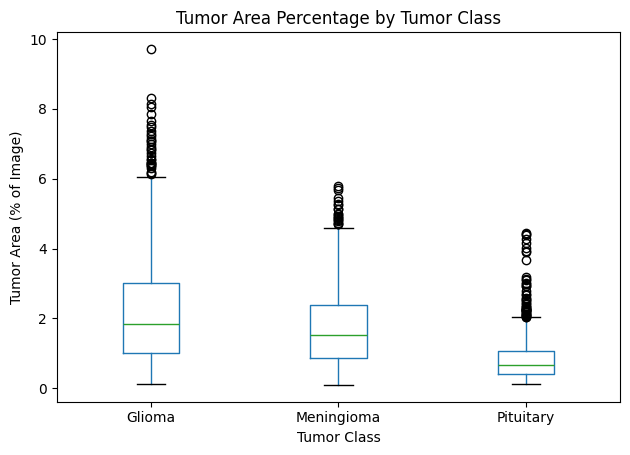

In [33]:
# ============================================================
# 22.4 TUMOR AREA COMPARISON BY CLASS
# ============================================================
# Purpose:
# Visualize differences in tumor area distributions between
# meningioma, glioma, and pituitary tumor images.
# ============================================================

plt.figure(figsize=(9, 6))

figshare_df.boxplot(
    column="tumor_area_percentage",
    by="class",
    grid=False
)

plt.title("Tumor Area Percentage by Tumor Class")
plt.suptitle("")
plt.xlabel("Tumor Class")
plt.ylabel("Tumor Area (% of Image)")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_tumor_area_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# ============================================================
# 22.5 CHECK FOR EMPTY OR VERY SMALL TUMOR MASKS
# ============================================================
# Purpose:
# Identify images where the tumor mask contains no pixels or
# an unusually small number of tumor pixels.
#
# These cases are not automatically removed. They are flagged
# for investigation.
# ============================================================

zero_tumor = figshare_df[
    figshare_df["tumor_pixels"] == 0
]

very_small_tumor = figshare_df[
    figshare_df["tumor_area_percentage"] < 0.1
]

print(
    "Images with zero tumor pixels:",
    len(zero_tumor)
)

print(
    "Images with tumor area < 0.1%:",
    len(very_small_tumor)
)

Images with zero tumor pixels: 0
Images with tumor area < 0.1%: 1


In [35]:
# ============================================================
# 22.6 SAVE TUMOR AREA SUMMARY
# ============================================================
# Purpose:
# Save the class-level tumor area statistics for use in the
# EDA report and final presentation.
# ============================================================

tumor_area_by_class.to_csv(
    results_dir / "figshare_tumor_area_by_class.csv"
)

print("Tumor area summary saved successfully.")

Tumor area summary saved successfully.


In [36]:
# ============================================================
# 22.7 IDENTIFY THE EXTREMELY SMALL TUMOR REGION
# ============================================================
# Purpose:
# Identify the MRI image containing the smallest tumor region.
# ============================================================

small_tumor = figshare_df[
    figshare_df["tumor_area_percentage"] < 0.1
].copy()

print("Number of images with tumor area < 0.1%:", len(small_tumor))

print(
    small_tumor[
        [
            "filename",
            "pid",
            "class",
            "height",
            "width",
            "tumor_pixels",
            "tumor_area_percentage"
        ]
    ].to_string(index=False)
)

Number of images with tumor area < 0.1%: 1
filename    pid      class  height  width  tumor_pixels  tumor_area_percentage
 577.mat 109350 Meningioma     512    512           255               0.097275


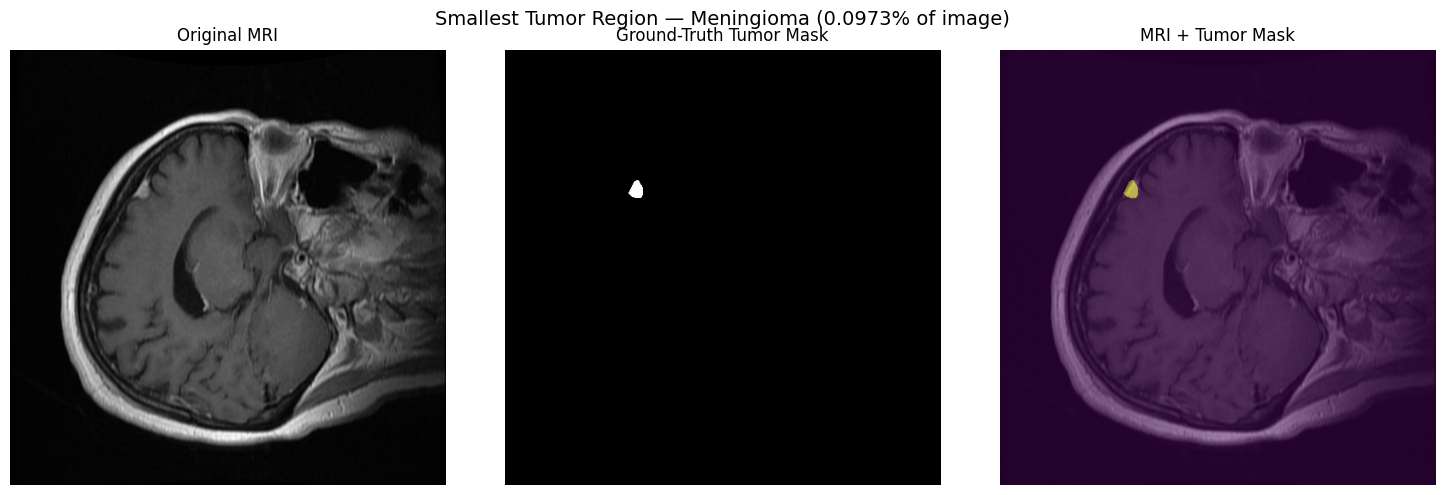

In [37]:
# ============================================================
# 22.8 VISUAL INSPECTION OF THE SMALLEST TUMOR REGION
# ============================================================
# Purpose:
# Visually inspect the MRI and its ground-truth tumor mask.
#
# The purpose is to determine whether the very small tumor
# annotation appears valid.
# ============================================================

row = small_tumor.iloc[0]

# Open the corresponding MATLAB file
with h5py.File(row["file"], "r") as f:

    # Extract MRI image
    image = np.array(
        f["cjdata"]["image"]
    )

    # Extract tumor mask
    tumor_mask = np.array(
        f["cjdata"]["tumorMask"]
    )

# Create three-panel visualization
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

# Original MRI
axes[0].imshow(
    image,
    cmap="gray"
)
axes[0].set_title("Original MRI")
axes[0].axis("off")

# Tumor mask
axes[1].imshow(
    tumor_mask,
    cmap="gray"
)
axes[1].set_title("Ground-Truth Tumor Mask")
axes[1].axis("off")

# Overlay
axes[2].imshow(
    image,
    cmap="gray"
)
axes[2].imshow(
    tumor_mask,
    alpha=0.5
)
axes[2].set_title("MRI + Tumor Mask")
axes[2].axis("off")

plt.suptitle(
    f"Smallest Tumor Region — {row['class']} "
    f"({row['tumor_area_percentage']:.4f}% of image)",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_smallest_tumor_inspection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# ============================================================
# 23.1 PIXEL INTENSITY STATISTICS
# ============================================================
# Purpose:
# Calculate basic pixel-intensity statistics for every MRI image.
#
# Images are processed one at a time to avoid loading all MRI
# arrays into memory simultaneously.
# ============================================================

intensity_records = []

for file_path in tqdm(
    mat_files,
    desc="Calculating intensity statistics"
):

    try:
        # Open one MATLAB v7.3 file
        with h5py.File(file_path, "r") as f:

            # Extract the MRI image
            image = np.array(
                f["cjdata"]["image"],
                dtype=np.float32
            )

            # Calculate descriptive intensity statistics
            intensity_records.append({
                "filename": file_path.name,
                "min_intensity": float(image.min()),
                "max_intensity": float(image.max()),
                "mean_intensity": float(image.mean()),
                "std_intensity": float(image.std())
            })

    except Exception as e:
        print(f"Error processing {file_path}: {e}")

# Convert intensity statistics into a DataFrame
intensity_df = pd.DataFrame(intensity_records)

print("Number of images analyzed:", len(intensity_df))

intensity_df.head()

Calculating intensity statistics:   0%|          | 0/3064 [00:00<?, ?it/s]

Number of images analyzed: 3064


,filename,min_intensity,max_intensity,mean_intensity,std_intensity
0,1533.mat,0.0,2662.0,527.955139,423.694885
1,1534.mat,0.0,2583.0,540.465820,431.438141
2,1535.mat,0.0,2685.0,549.704773,432.813538
3,1536.mat,0.0,2938.0,562.673340,439.261322
4,1537.mat,0.0,2934.0,568.198242,440.193268


In [39]:
# ============================================================
# 23.2 OVERALL INTENSITY SUMMARY
# ============================================================
# Purpose:
# Summarize the distribution of MRI pixel intensities across
# the complete dataset.
# ============================================================

print(
    intensity_df[
        [
            "min_intensity",
            "max_intensity",
            "mean_intensity",
            "std_intensity"
        ]
    ].describe()
)

       min_intensity  max_intensity  mean_intensity  std_intensity
count         3064.0    3064.000000     3064.000000    3064.000000
mean             0.0    3390.139034      467.385597     523.479563
std              0.0    2146.146428      215.988594     291.206772
min              0.0     238.000000       44.886505      34.894821
25%              0.0    1999.750000      309.202156     334.603455
50%              0.0    2950.000000      479.450729     492.536194
75%              0.0    4476.500000      604.205643     698.195450
max              0.0   12728.000000     1238.030396    1644.918823


In [40]:
# ============================================================
# 23.3 MERGE INTENSITY DATA WITH DATASET METADATA
# ============================================================
# Purpose:
# Combine MRI intensity statistics with tumor class information
# so that intensity distributions can be compared across classes.
# ============================================================

figshare_analysis_df = figshare_df.merge(
    intensity_df,
    on="filename",
    how="left"
)

print(
    "Rows after merging:",
    len(figshare_analysis_df)
)

print(
    figshare_analysis_df[
        [
            "filename",
            "class",
            "mean_intensity",
            "std_intensity"
        ]
    ].head()
)

Rows after merging: 3064
   filename      class  mean_intensity  std_intensity
0  1533.mat  Pituitary      527.955139     423.694885
1  1534.mat  Pituitary      540.465820     431.438141
2  1535.mat  Pituitary      549.704773     432.813538
3  1536.mat  Pituitary      562.673340     439.261322
4  1537.mat  Pituitary      568.198242     440.193268


In [41]:
# ============================================================
# 23.4 MEAN INTENSITY BY TUMOR CLASS
# ============================================================
# Purpose:
# Compare the distribution of mean MRI intensity across the
# three tumor categories.
# ============================================================

mean_intensity_by_class = (
    figshare_analysis_df
    .groupby("class")["mean_intensity"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(class_order)
)

print(
    mean_intensity_by_class.round(3)
)

            count     mean   median      std      min       max
class                                                          
Meningioma    708  392.400  412.846  136.177   78.611   725.604
Glioma       1426  576.168  574.818  193.795  125.280  1238.030
Pituitary     930  357.671  326.560  218.156   44.887   889.630


<Figure size 900x600 with 0 Axes>

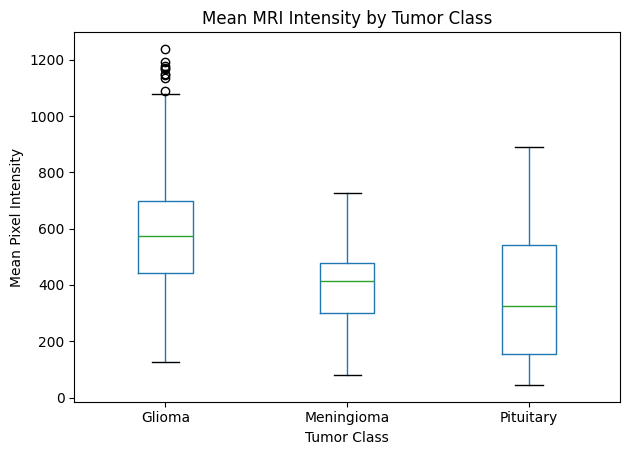

In [42]:
# ============================================================
# 23.5 MEAN INTENSITY DISTRIBUTION BY CLASS
# ============================================================
# Purpose:
# Visualize variation in average MRI intensity across the
# three tumor categories.
# ============================================================

plt.figure(figsize=(9, 6))

figshare_analysis_df.boxplot(
    column="mean_intensity",
    by="class",
    grid=False
)

plt.title("Mean MRI Intensity by Tumor Class")
plt.suptitle("")
plt.xlabel("Tumor Class")
plt.ylabel("Mean Pixel Intensity")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_mean_intensity_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
# ============================================================
# 23.6 OVERALL PIXEL INTENSITY DISTRIBUTION
# ============================================================
# Purpose:
# Visualize the overall distribution of MRI pixel intensities.
#
# A fixed number of pixels is sampled from each image to keep
# the analysis computationally manageable while maintaining
# reproducibility.
# ============================================================

rng = np.random.default_rng(42)

pixel_samples = []

# Number of pixels sampled from each image
pixels_per_image = 1000

for file_path in tqdm(
    mat_files,
    desc="Sampling MRI pixels"
):

    with h5py.File(file_path, "r") as f:

        # Load MRI image
        image = np.array(
            f["cjdata"]["image"],
            dtype=np.float32
        )

    # Flatten the image into a one-dimensional array
    pixels = image.ravel()

    # Sample pixels without replacement
    sample_size = min(
        pixels_per_image,
        len(pixels)
    )

    sampled_pixels = rng.choice(
        pixels,
        size=sample_size,
        replace=False
    )

    pixel_samples.extend(
        sampled_pixels
    )

print(
    "Total sampled pixels:",
    len(pixel_samples)
)

Sampling MRI pixels:   0%|          | 0/3064 [00:00<?, ?it/s]

Total sampled pixels: 3064000


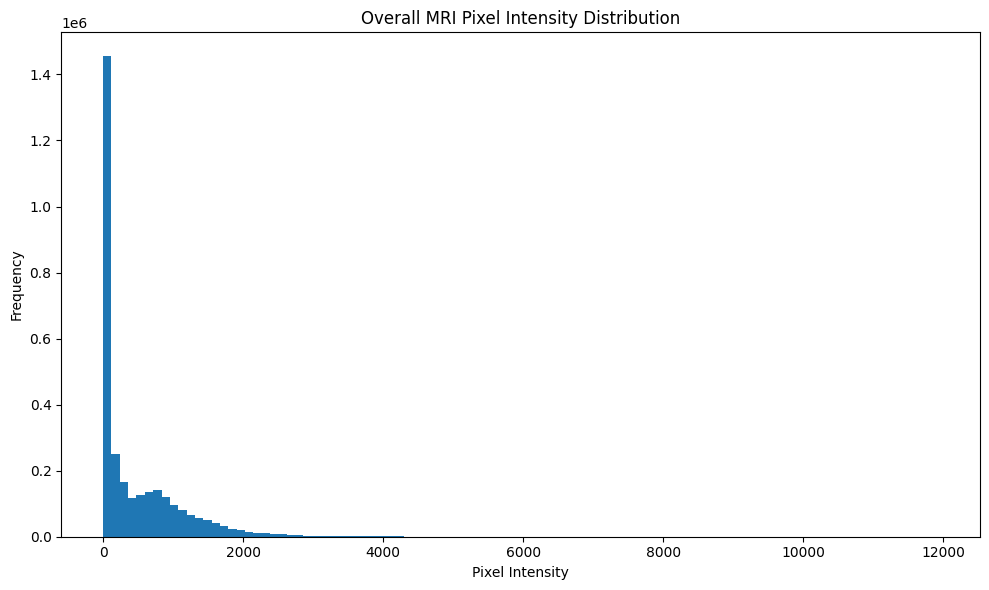

In [44]:
# ============================================================
# 23.7 PIXEL INTENSITY HISTOGRAM
# ============================================================
# Purpose:
# Visualize the overall distribution of sampled MRI pixel
# intensities.
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    pixel_samples,
    bins=100
)

plt.title(
    "Overall MRI Pixel Intensity Distribution"
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_pixel_intensity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
# ============================================================
# 23.8 SAVE INTENSITY ANALYSIS
# ============================================================
# Purpose:
# Save the calculated intensity statistics for reproducibility
# and future analysis.
# ============================================================

intensity_analysis_path = (
    results_dir / "figshare_intensity_statistics.csv"
)

figshare_analysis_df.to_csv(
    intensity_analysis_path,
    index=False
)

print(
    "Intensity statistics saved to:",
    intensity_analysis_path
)

Intensity statistics saved to: ..\results\eda\figshare_intensity_statistics.csv


In [46]:
print(mean_intensity_by_class.round(3))

            count     mean   median      std      min       max
class                                                          
Meningioma    708  392.400  412.846  136.177   78.611   725.604
Glioma       1426  576.168  574.818  193.795  125.280  1238.030
Pituitary     930  357.671  326.560  218.156   44.887   889.630


In [47]:
# ============================================================
# 24.1 TUMOR VS NON-TUMOR INTENSITY
# ============================================================
# Purpose:
# Calculate mean MRI intensity separately inside and outside
# the ground-truth tumor region for every image.
#
# The tumor mask provides the spatial separation between the
# two regions.
# ============================================================

region_intensity_records = []

for file_path in tqdm(
    mat_files,
    desc="Analyzing tumor and non-tumor intensity"
):

    try:
        # Open the MATLAB v7.3 file
        with h5py.File(file_path, "r") as f:

            # Extract MRI image
            image = np.array(
                f["cjdata"]["image"],
                dtype=np.float32
            )

            # Extract ground-truth tumor mask
            tumor_mask = np.array(
                f["cjdata"]["tumorMask"]
            )

        # Convert mask into a Boolean array
        tumor_region = tumor_mask > 0

        # Define the non-tumor region
        non_tumor_region = ~tumor_region

        # Calculate mean intensity inside the tumor
        tumor_mean = float(
            image[tumor_region].mean()
        )

        # Calculate mean intensity outside the tumor
        non_tumor_mean = float(
            image[non_tumor_region].mean()
        )

        # Calculate the difference between the two regions
        intensity_difference = (
            tumor_mean - non_tumor_mean
        )

        region_intensity_records.append({
            "filename": file_path.name,
            "tumor_mean_intensity": tumor_mean,
            "non_tumor_mean_intensity": non_tumor_mean,
            "tumor_non_tumor_difference": intensity_difference
        })

    except Exception as e:
        print(f"Error processing {file_path}: {e}")

# Convert results into a DataFrame
region_intensity_df = pd.DataFrame(
    region_intensity_records
)

print(
    "Images analyzed:",
    len(region_intensity_df)
)

region_intensity_df.head()


Analyzing tumor and non-tumor intensity:   0%|          | 0/3064 [00:00<?, ?it/s]

Images analyzed: 3064


,filename,tumor_mean_intensity,non_tumor_mean_intensity,tumor_non_tumor_difference
0,1533.mat,1141.282227,525.316528,615.965698
1,1534.mat,1431.690918,536.154480,895.536438
2,1535.mat,1418.822998,544.354187,874.468811
3,1536.mat,1375.023682,558.602905,816.420776
4,1537.mat,1261.657227,564.995850,696.661377


In [48]:
# ============================================================
# 24.2 MERGE REGION INTENSITY WITH METADATA
# ============================================================
# Purpose:
# Combine tumor/non-tumor intensity measurements with the
# corresponding tumor class.
# ============================================================

region_analysis_df = figshare_df.merge(
    region_intensity_df,
    on="filename",
    how="left"
)

print(
    "Rows after merging:",
    len(region_analysis_df)
)

Rows after merging: 3064


In [49]:
# ============================================================
# 24.3 REGION INTENSITY BY TUMOR CLASS
# ============================================================
# Purpose:
# Compare the mean intensity of tumor and non-tumor regions
# across meningioma, glioma, and pituitary tumor classes.
# ============================================================

region_intensity_by_class = (
    region_analysis_df
    .groupby("class")[
        [
            "tumor_mean_intensity",
            "non_tumor_mean_intensity",
            "tumor_non_tumor_difference"
        ]
    ]
    .agg(["mean", "median", "std"])
    .reindex(class_order)
)

print(
    region_intensity_by_class.round(3)
)

           tumor_mean_intensity                    non_tumor_mean_intensity  \
                           mean    median      std                     mean   
class                                                                         
Meningioma             1151.882  1129.346  448.498                  378.981   
Glioma                 1154.661  1095.864  505.920                  563.725   
Pituitary               785.112   567.090  570.822                  354.118   

                             tumor_non_tumor_difference                    
             median      std                       mean   median      std  
class                                                                      
Meningioma  398.063  132.134                    772.902  724.031  353.374  
Glioma      561.272  188.704                    590.937  507.651  395.598  
Pituitary   322.107  215.355                    430.994  253.591  383.420  


<Figure size 1000x600 with 0 Axes>

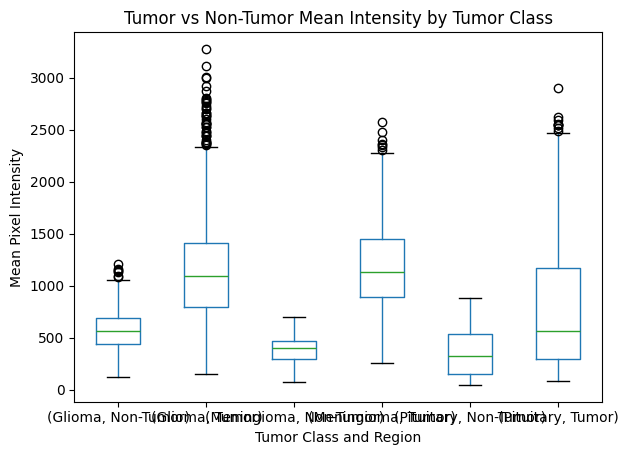

In [50]:
# ============================================================
# 24.4 TUMOR VS NON-TUMOR INTENSITY VISUALIZATION
# ============================================================
# Purpose:
# Visually compare the mean intensity of tumor and non-tumor
# regions across the three tumor categories.
# ============================================================

plot_data = region_analysis_df.melt(
    id_vars="class",
    value_vars=[
        "tumor_mean_intensity",
        "non_tumor_mean_intensity"
    ],
    var_name="Region",
    value_name="Mean Intensity"
)

# Make the region names easier to read
plot_data["Region"] = plot_data["Region"].replace({
    "tumor_mean_intensity": "Tumor",
    "non_tumor_mean_intensity": "Non-Tumor"
})

plt.figure(figsize=(10, 6))

plot_data.boxplot(
    column="Mean Intensity",
    by=["class", "Region"],
    grid=False
)

plt.title(
    "Tumor vs Non-Tumor Mean Intensity by Tumor Class"
)

plt.suptitle("")

plt.xlabel("Tumor Class and Region")
plt.ylabel("Mean Pixel Intensity")

plt.tight_layout()

plt.savefig(
    results_dir / "figshare_tumor_vs_non_tumor_intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
print(region_intensity_by_class.round(3))

           tumor_mean_intensity                    non_tumor_mean_intensity  \
                           mean    median      std                     mean   
class                                                                         
Meningioma             1151.882  1129.346  448.498                  378.981   
Glioma                 1154.661  1095.864  505.920                  563.725   
Pituitary               785.112   567.090  570.822                  354.118   

                             tumor_non_tumor_difference                    
             median      std                       mean   median      std  
class                                                                      
Meningioma  398.063  132.134                    772.902  724.031  353.374  
Glioma      561.272  188.704                    590.937  507.651  395.598  
Pituitary   322.107  215.355                    430.994  253.591  383.420  


In [53]:
# ============================================================
# 25.1 FILE READABILITY CHECK
# ============================================================
# Purpose:
# Verify that every MRI MATLAB file can be opened successfully.
#
# A file that cannot be opened may indicate corruption or an
# incomplete extraction.
# ============================================================

unreadable_files = []

for file_path in tqdm(
    mat_files,
    desc="Checking file readability"
):

    try:
        # Attempt to open the MATLAB v7.3 file
        with h5py.File(file_path, "r") as f:

            # Verify that the expected cjdata structure exists
            if "cjdata" not in f:
                unreadable_files.append(
                    (str(file_path), "Missing cjdata")
                )

    except Exception as e:
        unreadable_files.append(
            (str(file_path), str(e))
        )

print(
    "Unreadable/invalid files:",
    len(unreadable_files)
)

if unreadable_files:
    print("\nProblematic files:")
    for item in unreadable_files:
        print(item)
else:
    print("All 3,064 MATLAB files are readable.")

Checking file readability:   0%|          | 0/3064 [00:00<?, ?it/s]

Unreadable/invalid files: 0
All 3,064 MATLAB files are readable.


In [54]:
# ============================================================
# 25.2 BLANK IMAGE CHECK
# ============================================================
# Purpose:
# Identify completely uniform MRI images.
#
# An image with zero intensity variation is potentially blank
# or corrupted and should be investigated.
# ============================================================

blank_images = []

for file_path in tqdm(
    mat_files,
    desc="Checking for blank images"
):

    with h5py.File(file_path, "r") as f:

        # Load MRI image
        image = np.array(
            f["cjdata"]["image"]
        )

    # Calculate intensity variation
    image_std = image.std()

    # A standard deviation of zero means all pixels are identical
    if image_std == 0:
        blank_images.append(str(file_path))

print(
    "Completely blank/uniform images:",
    len(blank_images)
)

if blank_images:
    print("\nPotentially problematic images:")
    for file_path in blank_images:
        print(file_path)
else:
    print("No completely uniform MRI images were detected.")

Checking for blank images:   0%|          | 0/3064 [00:00<?, ?it/s]

Completely blank/uniform images: 0
No completely uniform MRI images were detected.


In [55]:
# ============================================================
# 25.3 EXACT DUPLICATE IMAGE CHECK
# ============================================================
# Purpose:
# Identify MRI images that have exactly identical pixel values.
#
# Exact duplicates can cause unintended data repetition and may
# influence model evaluation if they cross dataset partitions.
# ============================================================

import hashlib

image_hashes = {}

for file_path in tqdm(
    mat_files,
    desc="Checking for duplicate images"
):

    with h5py.File(file_path, "r") as f:

        # Load MRI image
        image = np.array(
            f["cjdata"]["image"]
        )

    # Convert image pixels into bytes
    image_bytes = image.tobytes()

    # Generate a SHA-256 hash
    image_hash = hashlib.sha256(
        image_bytes
    ).hexdigest()

    # Store the file associated with this hash
    image_hashes.setdefault(
        image_hash,
        []
    ).append(str(file_path))

# Identify hashes associated with multiple files
duplicate_groups = {
    image_hash: files
    for image_hash, files in image_hashes.items()
    if len(files) > 1
}

print(
    "Number of duplicate groups:",
    len(duplicate_groups)
)

duplicate_image_count = sum(
    len(files)
    for files in duplicate_groups.values()
)

print(
    "Images belonging to duplicate groups:",
    duplicate_image_count
)

Checking for duplicate images:   0%|          | 0/3064 [00:00<?, ?it/s]

Number of duplicate groups: 0
Images belonging to duplicate groups: 0


In [56]:
# ============================================================
# 25.4 METADATA CONSISTENCY CHECK
# ============================================================
# Purpose:
# Confirm that the number of metadata records matches the
# number of MRI files and that all expected classes are present.
# ============================================================

print(
    "MRI files discovered:",
    len(mat_files)
)

print(
    "Metadata records:",
    len(figshare_df)
)

print(
    "Unique classes:",
    figshare_df["class"].nunique()
)

print(
    "Classes:",
    sorted(figshare_df["class"].unique())
)

# Verify that the expected three classes are present
expected_classes = {
    "Meningioma",
    "Glioma",
    "Pituitary"
}

actual_classes = set(
    figshare_df["class"].unique()
)

print(
    "\nClass labels valid:",
    actual_classes == expected_classes
)

MRI files discovered: 3064
Metadata records: 3064
Unique classes: 3
Classes: ['Glioma', 'Meningioma', 'Pituitary']

Class labels valid: True


In [57]:
# ============================================================
# 25.5 FINAL QUALITY-CONTROL SUMMARY
# ============================================================
# Purpose:
# Create a compact summary of the final dataset quality checks.
# ============================================================

qc_summary = pd.DataFrame({
    "Check": [
        "Total MRI files",
        "Metadata records",
        "Unreadable files",
        "Blank/uniform images",
        "Duplicate groups",
        "Empty tumor masks",
        "Images with tumor area < 0.1%"
    ],
    "Result": [
        len(mat_files),
        len(figshare_df),
        len(unreadable_files),
        len(blank_images),
        len(duplicate_groups),
        len(
            figshare_df[
                figshare_df["tumor_pixels"] == 0
            ]
        ),
        len(
            figshare_df[
                figshare_df["tumor_area_percentage"] < 0.1
            ]
        )
    ]
})

print(qc_summary)

                           Check  Result
0                Total MRI files    3064
1               Metadata records    3064
2               Unreadable files       0
3           Blank/uniform images       0
4               Duplicate groups       0
5              Empty tumor masks       0
6  Images with tumor area < 0.1%       1


In [58]:
# Save the final quality-control summary
qc_summary.to_csv(
    results_dir / "figshare_quality_control_summary.csv",
    index=False
)

print("Quality-control summary saved successfully.")

Quality-control summary saved successfully.


# 26. Final EDA Findings

## Dataset Overview

The Figshare brain tumor dataset contains 3,064 T1-weighted
contrast-enhanced MRI images obtained from 233 patients.

The dataset contains three tumor categories:

- Meningioma
- Glioma
- Pituitary tumor

## Class Distribution

The dataset contains 708 meningioma, 1,426 glioma, and 930
pituitary tumor images. Therefore, the dataset exhibits class
imbalance, with glioma representing the largest class.

This motivates the use of class-aware evaluation metrics such as
macro-F1, precision, recall, and per-class confusion matrices
during model evaluation.

## Patient-Level Structure

The 3,064 MRI images originate from only 233 patients. Each patient
contributes between 1 and 38 images, with a median of 13 images
per patient.

Therefore, image-level random splitting could result in images
from the same patient appearing in different data partitions.
Patient-level splitting should consequently be used during model
development to reduce the risk of data leakage.

## Image Resolution

Most images have a resolution of 512 × 512 pixels, while 15 images
have a resolution of 256 × 256 pixels.

These images were retained during EDA. Resolution standardization
should be handled during the preprocessing stage rather than
removing samples solely because of their original resolution.

## Tumor Segmentation

All 3,064 images contain non-empty tumor masks. The availability
of ground-truth tumor masks provides valuable spatial information
about the tumor regions.

This is particularly important for the proposed explainable
Vision Transformer framework because the ground-truth masks can
later be used to quantitatively evaluate the spatial alignment
between model attention/explainability maps and tumor regions.

## Tumor Area

Tumor area percentages vary across the dataset and across tumor
classes. Only one image contains a tumor region occupying less
than 0.1% of the image.

The tumor-area analysis provides useful information about the
variation in tumor extent within the dataset.

## Pixel Intensity

MRI pixel-intensity distributions vary across tumor classes.
Tumor regions generally show higher mean intensity than the
corresponding non-tumor regions in this dataset.

These observations are descriptive and should not be interpreted
as independent clinical biomarkers because MRI intensity can be
affected by acquisition and preprocessing conditions.

## Data Quality

All 3,064 MRI files were successfully read.

No unreadable files, completely uniform images, duplicate image
groups, or empty tumor masks were detected.

Therefore, the dataset passed the major data-quality checks
performed during EDA.

## Overall Conclusion

The Figshare dataset provides a strong foundation for the proposed
brain tumor detection and explainability project.

Its combination of tumor class labels, patient identifiers,
MRI images, tumor boundaries, and ground-truth tumor masks enables
not only multiclass tumor classification but also quantitative
investigation of model attention and explainability.

The EDA findings will guide subsequent preprocessing, patient-level
data partitioning, Vision Transformer training, and quantitative
evaluation of attention-based explanations.

## EDA Summary Table

| Analysis | Key Finding | Modeling Implication |
|---|---|---|
| Dataset size | 3,064 images / 233 patients | Patient-level splitting |
| Classes | 3 tumor categories | Multiclass classification |
| Class balance | Glioma is the largest class | Use macro-F1 and per-class metrics |
| Patient images | 1–38 images/patient | Avoid patient-level leakage |
| Resolution | 3,049 at 512×512; 15 at 256×256 | Standardize during preprocessing |
| Tumor masks | 0 empty masks | Enables localization/XAI evaluation |
| Tumor area | 1 image <0.1% | Retain and investigate |
| Intensity | Class/region differences observed | Apply appropriate normalization |
| File integrity | 0 unreadable files | Dataset successfully validated |
| Duplicates | 0 exact duplicate groups | No exact duplicate issue detected |